### Wrapper Methods

Wrapper methods select features by repeatedly training and evaluating a machine learning model on different feature subsets. Instead of measuring features independently, they use the performance of a chosen model to decide which subset works best.

They can find useful combinations of features, but they are usually more computationally expensive than filter methods because the model is trained many times. In this notebook, we explore Exhaustive Feature Selection, Sequential Backward Elimination, Sequential Forward Selection, and Recursive Feature Elimination (RFE).

### Exhaustive Feature Selection 

**How it works :** Exhaustive Feature Selection (EFS) evaluates every possible feature combination within the specified feature-count limits. It selects the subset with the best cross-validation score.

**Advantages**
- Searches combinations systematically, so it can find strong feature subsets.
- Considers interactions between features through model performance.
- Provides scores for the evaluated subsets, making comparisons possible.

**Disadvantages**
- The number of combinations grows rapidly as the number of features increases.
- Can be very slow and resource-intensive on datasets with many features.
- The selected subset depends on the estimator, scoring metric, and cross-validation setup.

In [1]:
import pandas as pd 
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_score

In [2]:
df = pd.read_csv("Datasets/iris.csv")

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


#### Logistic Regression Example 

In [4]:
from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS 

lr = LogisticRegression()

sel = EFS(lr, max_features=5, scoring='accuracy', cv=5)

In [5]:
# train model for ervery subset 
model = sel.fit(df.iloc[:,:5], df['Species'])

C:\Users\us\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\us\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/m

In [6]:
model.best_score_

np.float64(0.9733333333333334)

In [7]:
model.best_feature_names_

('SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm')

In [8]:
# detaild subsets
model.subsets_

{0: {'feature_idx': (0,),
  'cv_scores': array([0.66666667, 1.        , 1.        , 1.        , 0.66666667]),
  'avg_score': np.float64(0.8666666666666666),
  'feature_names': ('Id',)},
 1: {'feature_idx': (1,),
  'cv_scores': array([0.66666667, 0.73333333, 0.76666667, 0.76666667, 0.83333333]),
  'avg_score': np.float64(0.7533333333333333),
  'feature_names': ('SepalLengthCm',)},
 2: {'feature_idx': (2,),
  'cv_scores': array([0.53333333, 0.56666667, 0.53333333, 0.53333333, 0.63333333]),
  'avg_score': np.float64(0.5599999999999999),
  'feature_names': ('SepalWidthCm',)},
 3: {'feature_idx': (3,),
  'cv_scores': array([0.93333333, 1.        , 0.9       , 0.93333333, 1.        ]),
  'avg_score': np.float64(0.9533333333333334),
  'feature_names': ('PetalLengthCm',)},
 4: {'feature_idx': (4,),
  'cv_scores': array([1.        , 0.96666667, 0.9       , 0.93333333, 1.        ]),
  'avg_score': np.float64(0.96),
  'feature_names': ('PetalWidthCm',)},
 5: {'feature_idx': (0, 1),
  'cv_scores':

In [9]:
metric_df = pd.DataFrame(model.get_metric_dict()).T
metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
0,"(0,)","[0.6666666666666666, 1.0, 1.0, 1.0, 0.66666666...",0.866667,"(Id,)",0.209887,0.163299,0.08165
1,"(1,)","[0.6666666666666666, 0.7333333333333333, 0.766...",0.753333,"(SepalLengthCm,)",0.069612,0.05416,0.02708
2,"(2,)","[0.5333333333333333, 0.5666666666666667, 0.533...",0.56,"(SepalWidthCm,)",0.049963,0.038873,0.019437
3,"(3,)","[0.9333333333333333, 1.0, 0.9, 0.9333333333333...",0.953333,"(PetalLengthCm,)",0.051412,0.04,0.02
4,"(4,)","[1.0, 0.9666666666666667, 0.9, 0.9333333333333...",0.96,"(PetalWidthCm,)",0.049963,0.038873,0.019437
5,"(0, 1)","[0.6666666666666666, 1.0, 1.0, 1.0, 0.66666666...",0.866667,"(Id, SepalLengthCm)",0.209887,0.163299,0.08165
6,"(0, 2)","[0.6666666666666666, 1.0, 1.0, 1.0, 0.66666666...",0.866667,"(Id, SepalWidthCm)",0.209887,0.163299,0.08165
7,"(0, 3)","[0.7333333333333333, 1.0, 1.0, 1.0, 0.7]",0.886667,"(Id, PetalLengthCm)",0.178918,0.139204,0.069602
8,"(0, 4)","[0.6666666666666666, 1.0, 1.0, 1.0, 0.66666666...",0.866667,"(Id, PetalWidthCm)",0.209887,0.163299,0.08165
9,"(1, 2)","[0.7333333333333333, 0.8333333333333334, 0.766...",0.82,"(SepalLengthCm, SepalWidthCm)",0.079462,0.061824,0.030912


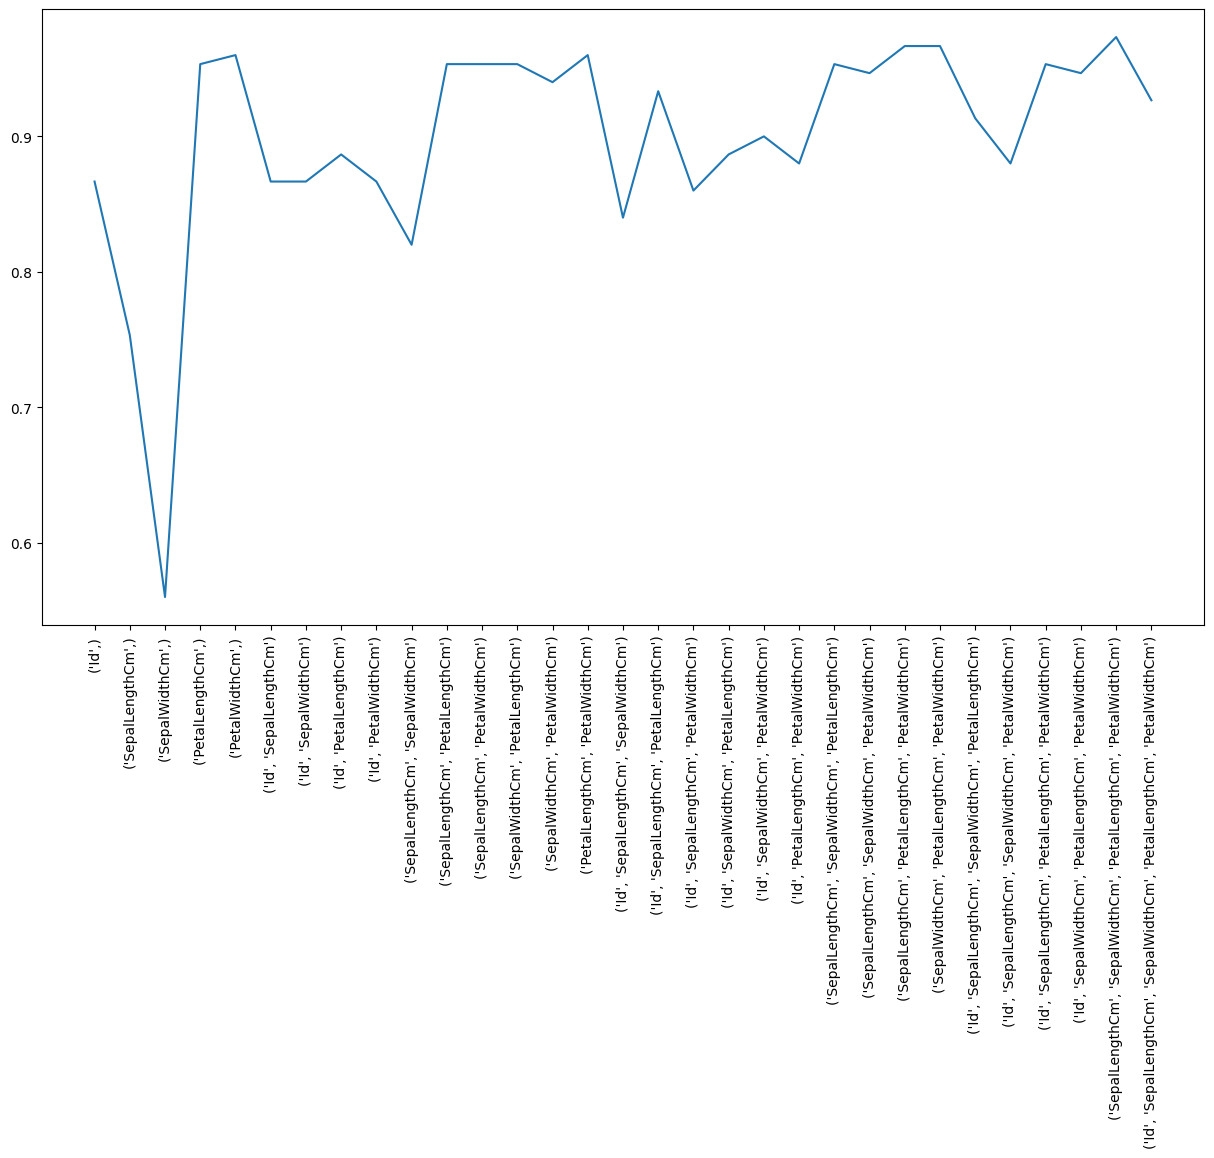

In [10]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(15,8))
plt.plot([str(i) for i in metric_df['feature_names']], metric_df['avg_score'])
plt.xticks(rotation=90)
plt.show()

#### Linear Regression Example 

In [11]:
df2 = pd.read_csv('Datasets/boston_housing.csv')
df2.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [12]:
X = df2.iloc[:, :13]
y = df2['medv']

In [13]:
X

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48


In [14]:
y

0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: medv, Length: 506, dtype: float64

##### Before Applying feature Selection 

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=2)

In [16]:
print(X_train.shape)
print(X_test.shape)

(404, 13)
(102, 13)


In [17]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [18]:
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)

In [19]:
X_train

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,-0.377439,-0.474570,-0.583731,-0.278089,-0.538118,0.129286,-0.531579,0.351594,-0.518452,-0.725706,0.523591,0.453913,-0.834106
1,-0.389187,-0.474570,-0.789684,-0.278089,-0.485944,-0.621116,-0.992951,0.064463,-0.518452,-0.773226,0.331552,0.453913,-0.563408
2,-0.396192,3.166089,-1.398840,-0.278089,-1.477250,-0.079001,-1.353398,2.506174,-0.980569,-0.998945,-0.148545,-0.134420,0.029277
3,-0.395308,-0.474570,-0.628693,-0.278089,-0.746814,1.283420,-0.286475,0.553705,-0.865040,-0.993005,-0.340584,0.410612,-1.238728
4,-0.301127,-0.474570,-0.473503,-0.278089,-0.146813,-0.979197,0.600224,0.310955,-0.633981,-0.606906,1.195727,-0.540615,0.539329
...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,-0.255739,-0.474570,-0.473503,-0.278089,-0.146813,-0.204543,0.816493,0.084688,-0.633981,-0.606906,1.195727,0.453913,0.854193
400,-0.387856,-0.474570,-0.086254,-0.278089,-1.233771,-0.314393,-2.207657,0.705370,-0.633981,-0.618786,0.331552,0.390185,-1.026444
401,-0.378397,-0.474570,-0.248696,-0.278089,0.261884,-0.825122,-0.542392,-0.670893,-0.402923,-0.107949,0.331552,0.453913,-0.101797
402,-0.325812,-0.474570,-0.473503,-0.278089,-0.146813,-0.643942,-0.452281,0.331796,-0.633981,-0.606906,1.195727,0.440295,-0.606150


In [20]:
from sklearn.metrics import r2_score

model = LinearRegression()

print("training",np.mean(cross_val_score(model, X_train, y_train, cv=5, scoring='r2')))
print("testing",np.mean(cross_val_score(model, X_test, y_test, cv=5, scoring='r2')))

training 0.7050401205374819
testing 0.6881584642617279


##### After Applying feature Selection 

In [21]:
model = LinearRegression()

exh = EFS(model, max_features=13, scoring='r2', cv=10, print_progress=True, n_jobs=-1)

In [22]:
sel = exh.fit(X_train, y_train)

Features: 8191/8191

In [23]:
sel.best_score_

np.float64(0.6908017709038575)

In [24]:
sel.best_feature_names_

('crim',
 'zn',
 'chas',
 'nox',
 'rm',
 'dis',
 'rad',
 'tax',
 'ptratio',
 'b',
 'lstat')

In [25]:
metric_df = pd.DataFrame.from_dict(sel.get_metric_dict()).T

In [26]:
metric_df.head()

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
0,"(0,)","[0.21114948846401937, 0.05617257789397889, 0.1...",0.090584,"(crim,)",0.058456,0.078706,0.026235
1,"(1,)","[0.10024498418931094, 0.057415019085727104, -0...",0.08041,"(zn,)",0.059363,0.079927,0.026642
2,"(2,)","[0.18401775043295243, 0.10274194717127505, 0.1...",0.18668,"(indus,)",0.084623,0.113938,0.037979
3,"(3,)","[0.07730135125361781, 0.035964826531153404, -0...",0.027614,"(chas,)",0.049668,0.066874,0.022291
4,"(4,)","[0.24448453708830642, 0.10867049515410976, 0.0...",0.139739,"(nox,)",0.096446,0.129856,0.043285


In [27]:
metric_df.shape

(8191, 7)

In [28]:
def adj_r2(r2, num_examaples, num_feature): 
    coef = (num_examaples - 1) / (num_examaples - num_feature - 1)
    return 1 - (1-r2) * coef

In [29]:
metric_df['observation'] = 404 
metric_df['num_features'] = metric_df['feature_idx'].apply(lambda x:len(x))

In [30]:
metric_df.sample(5)

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observation,num_features
4633,"(0, 2, 3, 5, 7, 9, 11)","[0.5306566424171637, 0.6971084312641894, 0.423...",0.552347,"(crim, indus, chas, rm, dis, tax, b)",0.11577,0.155874,0.051958,404,7
5907,"(0, 1, 2, 3, 6, 7, 9, 11)","[0.39571720299540014, 0.4225390827851495, 0.22...",0.362814,"(crim, zn, indus, chas, age, dis, tax, b)",0.066652,0.089741,0.029914,404,8
368,"(8, 9, 11)","[0.2579922130799529, 0.200534522178613, 0.1804...",0.195569,"(rad, tax, b)",0.074175,0.09987,0.03329,404,3
6835,"(1, 3, 4, 5, 7, 8, 9, 12)","[0.5741782880665843, 0.7807953496259876, 0.615...",0.637103,"(zn, chas, nox, rm, dis, rad, tax, lstat)",0.078922,0.106262,0.035421,404,8
1125,"(0, 1, 2, 7, 11)","[0.31151190256521044, 0.32292972160501265, 0.2...",0.29699,"(crim, zn, indus, dis, b)",0.041379,0.055714,0.018571,404,5


In [31]:
metric_df['adjusted_r2_score'] = adj_r2(metric_df['avg_score'], metric_df['observation'], metric_df['num_features'])

In [32]:
metric_df.sample(5)

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observation,num_features,adjusted_r2_score
34,"(1, 11)","[0.21629942268386038, 0.1336468574032832, 0.03...",0.16848,"(zn, b)",0.054919,0.073944,0.024648,404,2,0.164332
2297,"(4, 6, 7, 11, 12)","[0.4257959474348628, 0.5869848391803878, 0.621...",0.534235,"(nox, age, dis, b, lstat)",0.058103,0.078231,0.026077,404,5,0.528384
3689,"(2, 3, 5, 6, 7, 8)","[0.48735584707242563, 0.6531682273326482, 0.38...",0.529994,"(indus, chas, rm, age, dis, rad)",0.119656,0.161107,0.053702,404,6,0.52289
2355,"(5, 8, 9, 11, 12)","[0.5609408527944709, 0.6996098621643958, 0.560...",0.607063,"(rm, rad, tax, b, lstat)",0.083763,0.112779,0.037593,404,5,0.602126
2293,"(4, 6, 7, 9, 11)","[0.2398455705523952, 0.23831260952261646, 0.21...",0.227263,"(nox, age, dis, tax, b)",0.066738,0.089857,0.029952,404,5,0.217555


In [33]:
metric_df.sort_values('adjusted_r2_score', ascending=False)

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observation,num_features,adjusted_r2_score
8029,"(0, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.6074602842383303, 0.8005826789942027, 0.647...",0.690479,"(crim, chas, nox, rm, dis, rad, tax, ptratio, ...",0.075194,0.101243,0.033748,404,10,0.682603
8150,"(0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.6181802912059224, 0.8096041951792724, 0.652...",0.690802,"(crim, zn, chas, nox, rm, dis, rad, tax, ptrat...",0.078195,0.105283,0.035094,404,11,0.682125
8160,"(0, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.6074758898705045, 0.7999812169543883, 0.648...",0.69011,"(crim, indus, chas, nox, rm, dis, rad, tax, pt...",0.075211,0.101265,0.033755,404,11,0.681414
8183,"(0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.617975283389933, 0.8092438980436961, 0.6527...",0.690373,"(crim, zn, indus, chas, nox, rm, dis, rad, tax...",0.078243,0.105348,0.035116,404,12,0.680871
8164,"(0, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.6011462005712244, 0.8004653998340788, 0.647...",0.688572,"(crim, chas, nox, rm, age, dis, rad, tax, ptra...",0.075562,0.101738,0.033913,404,11,0.679833
...,...,...,...,...,...,...,...,...,...,...
0,"(0,)","[0.21114948846401937, 0.05617257789397889, 0.1...",0.090584,"(crim,)",0.058456,0.078706,0.026235,404,1,0.088321
1,"(1,)","[0.10024498418931094, 0.057415019085727104, -0...",0.08041,"(zn,)",0.059363,0.079927,0.026642,404,1,0.078122
30,"(1, 7)","[0.10039807747216667, 0.03616860718050863, -0....",0.070362,"(zn, dis)",0.061171,0.082361,0.027454,404,2,0.065726
7,"(7,)","[0.09784323368776848, -0.0634713321307947, -0....",0.027929,"(dis,)",0.068829,0.092673,0.030891,404,1,0.025511


In [34]:
X_train_sel = sel.transform(X_train)
X_test_sel = sel.transform(X_test)

In [35]:
model = LinearRegression()

In [36]:
print('Training ', np.mean(cross_val_score(model, X_train_sel, y_train, cv=5, scoring='r2')))
print('Testing ', np.mean(cross_val_score(model, X_test_sel, y_test, cv=5, scoring='r2')))

Training  0.7064800467817652
Testing  0.6801687887814347


### Sequential Backward Elimination

**How it works :** Sequential Backward Elimination starts with all available features and removes one feature at a time. At each step, it keeps the removal that gives the best validation score, until the selection criterion identifies the preferred subset.

**Advantages**
- Starts with the complete feature set, so initially no feature is excluded.
- Can be useful when most features are expected to contribute information.
- Evaluates feature subsets using the chosen model and scoring metric.

**Disadvantages**
- Requires repeated model fitting and can be slow for large feature sets.
- A feature removed early is generally not reconsidered in basic backward selection.
- Results can depend on the estimator, scoring metric, and cross-validation folds.

In [37]:
df2

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [38]:
# separate the target variable
X = df2.drop("medv", axis=1)
y = df2['medv']

# split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print(X_train.shape)

(404, 13)


In [39]:
model = LinearRegression()

print("training",np.mean(cross_val_score(model, X_train, y_train, cv=5, scoring='r2')))
print("testing",np.mean(cross_val_score(model, X_test, y_test, cv=5, scoring='r2')))

training 0.7025123301096217
testing 0.6514899901155449


In [40]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
lr = LinearRegression()

# perform backward elimination
sfs = SFS(lr, k_features='best', forward=False, floating=False, scoring='r2',cv=5)

sfs.fit(X_train, y_train)

SequentialFeatureSelector(estimator=LinearRegression(), forward=False,
                          k_features=(1, 13), scoring='r2')

In [41]:
sfs.k_feature_idx_

(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)

In [42]:
metric_df = pd.DataFrame.from_dict(sfs.get_metric_dict()).T

metric_df['observations'] = 404
metric_df['num_features'] = metric_df['feature_idx'].apply(lambda x:len(x))
metric_df['adjusted_r2'] = adj_r2(metric_df['avg_score'],metric_df['observations'],metric_df['num_features'])

metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observations,num_features,adjusted_r2
13,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.7535027170817181, 0.6920238509138802, 0.682...",0.702512,"(crim, zn, indus, chas, nox, rm, age, dis, rad...",0.038207,0.029727,0.014863,404,13,0.692596
12,"(0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7532855958710685, 0.694457047769532, 0.6931...",0.70581,"(crim, zn, indus, chas, nox, rm, dis, rad, tax...",0.035641,0.02773,0.013865,404,12,0.696781
11,"(0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7547108925568484, 0.6959627893665093, 0.701...",0.708109,"(crim, zn, chas, nox, rm, dis, rad, tax, ptrat...",0.035367,0.027516,0.013758,404,11,0.699918
10,"(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7769593921905552, 0.6884741223718954, 0.702...",0.710033,"(crim, zn, nox, rm, dis, rad, tax, ptratio, b,...",0.046075,0.035848,0.017924,404,10,0.702654
9,"(0, 1, 4, 5, 7, 8, 9, 10, 12)","[0.770610422071101, 0.6854023389684323, 0.6900...",0.704324,"(crim, zn, nox, rm, dis, rad, tax, ptratio, ls...",0.046449,0.036139,0.018069,404,9,0.69757
8,"(0, 1, 4, 5, 7, 8, 10, 12)","[0.7681719744800475, 0.682212652681871, 0.6700...",0.697727,"(crim, zn, nox, rm, dis, rad, ptratio, lstat)",0.04882,0.037984,0.018992,404,8,0.691605
7,"(0, 1, 4, 5, 7, 10, 12)","[0.7671638009750728, 0.6812300799626652, 0.661...",0.692234,"(crim, zn, nox, rm, dis, ptratio, lstat)",0.051644,0.040181,0.02009,404,7,0.686794
6,"(1, 4, 5, 7, 10, 12)","[0.7519120213497097, 0.6756087674652569, 0.646...",0.686004,"(zn, nox, rm, dis, ptratio, lstat)",0.046845,0.036447,0.018224,404,6,0.681258
5,"(4, 5, 7, 10, 12)","[0.7525552802357779, 0.6665033988504312, 0.639...",0.681065,"(nox, rm, dis, ptratio, lstat)",0.051233,0.039861,0.019931,404,5,0.677058
4,"(5, 7, 10, 12)","[0.7384743962575444, 0.6401188507668834, 0.587...",0.662544,"(rm, dis, ptratio, lstat)",0.063384,0.049315,0.024658,404,4,0.659161


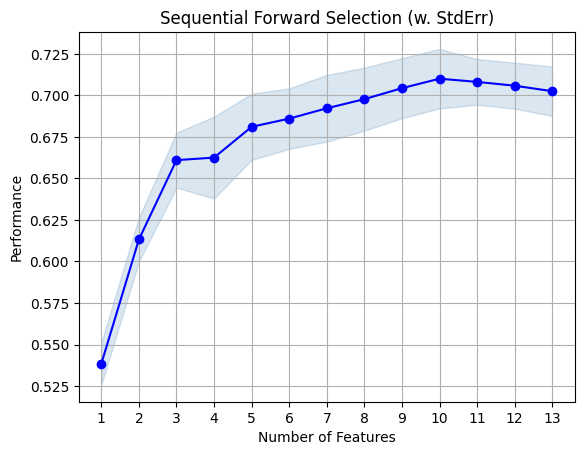

In [43]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs


fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err',)

plt.title('Sequential Forward Selection (w. StdErr)')
plt.grid()
plt.show()

In [44]:
X_train_sel = sfs.transform(X_train)
X_test_sel = sfs.transform(X_test)

model = LinearRegression()

print("training",np.mean(cross_val_score(model, X_train_sel, y_train, cv=5, scoring='r2')))
print("testing",np.mean(cross_val_score(model, X_test_sel, y_test, cv=5, scoring='r2')))

training 0.7100327839218556
testing 0.7205819296124478


In [45]:
X_train_sel.shape

(404, 10)

### Seuential Forward Selection 

**How it works :** Sequential Forward Selection starts with no features and adds one feature at a time. At each step, it adds the feature that produces the best validation score. The `floating=True` setting used below allows selected features to be conditionally removed during the search (Sequential Floating Forward Selection).

**Advantages**
- Often requires fewer evaluations than exhaustive search.
- Useful when only a small subset of all available features is expected to be important.
- Floating selection can revise earlier choices instead of only adding features.

**Disadvantages**
- Greedy search may not find the globally best feature combination.
- Features not selected at an earlier step may not be reconsidered in basic forward selection.
- Repeated model fitting makes it more expensive than simple filter methods.

In [46]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
lr = LinearRegression()

# perform backward elimination
sfs = SFS(lr, k_features='best', forward=True, floating=True, scoring='r2',cv=5)

sfs.fit(X_train, y_train)

SequentialFeatureSelector(estimator=LinearRegression(), floating=True,
                          k_features=(1, 13), scoring='r2')

In [47]:
sfs.k_feature_idx_

(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)

In [48]:
metric_df = pd.DataFrame.from_dict(sfs.get_metric_dict()).T

metric_df['observations'] = 404
metric_df['num_features'] = metric_df['feature_idx'].apply(lambda x:len(x))
metric_df['adjusted_r2'] = adj_r2(metric_df['avg_score'],metric_df['observations'],metric_df['num_features'])

metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observations,num_features,adjusted_r2
1,"(12,)","[0.5472998394577442, 0.49002001493399727, 0.53...",0.538451,"(lstat,)",0.032755,0.025485,0.012742,404,1,0.537303
2,"(5, 12)","[0.6330856272904801, 0.5779812120755249, 0.586...",0.613259,"(rm, lstat)",0.034066,0.026505,0.013252,404,2,0.61133
3,"(5, 10, 12)","[0.7215896884753017, 0.6288372046797157, 0.633...",0.661012,"(rm, ptratio, lstat)",0.04259,0.033136,0.016568,404,3,0.65847
4,"(5, 10, 11, 12)","[0.7258772165486238, 0.6342604286872177, 0.655...",0.667383,"(rm, ptratio, b, lstat)",0.039611,0.030819,0.01541,404,4,0.664048
5,"(5, 7, 10, 11, 12)","[0.744075617477433, 0.647344985815878, 0.61455...",0.671496,"(rm, dis, ptratio, b, lstat)",0.055057,0.042836,0.021418,404,5,0.667369
6,"(4, 5, 7, 10, 11, 12)","[0.7554472741494639, 0.6695521143038108, 0.653...",0.68562,"(nox, rm, dis, ptratio, b, lstat)",0.047626,0.037054,0.018527,404,6,0.680869
7,"(1, 4, 5, 7, 10, 11, 12)","[0.7548843433907446, 0.6798073590310524, 0.662...",0.6913,"(zn, nox, rm, dis, ptratio, b, lstat)",0.042762,0.03327,0.016635,404,7,0.685844
8,"(0, 1, 4, 5, 7, 10, 11, 12)","[0.767820153772997, 0.6827004362205147, 0.6713...",0.695442,"(crim, zn, nox, rm, dis, ptratio, b, lstat)",0.048774,0.037948,0.018974,404,8,0.689274
9,"(0, 1, 4, 5, 7, 8, 10, 11, 12)","[0.7746648196407364, 0.6850585456872305, 0.683...",0.703763,"(crim, zn, nox, rm, dis, rad, ptratio, b, lstat)",0.04762,0.03705,0.018525,404,9,0.696996
10,"(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7769593921905552, 0.6884741223718954, 0.702...",0.710033,"(crim, zn, nox, rm, dis, rad, tax, ptratio, b,...",0.046075,0.035848,0.017924,404,10,0.702654


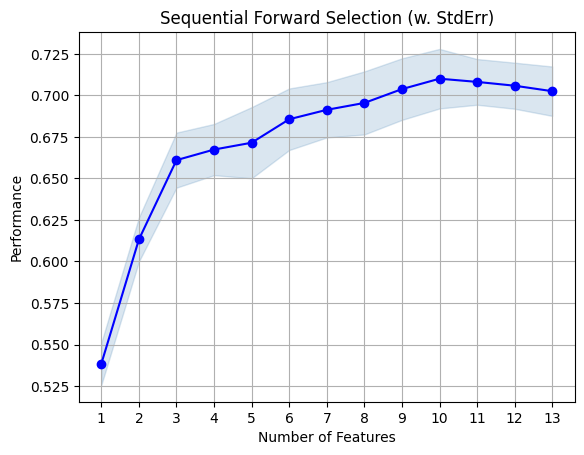

In [49]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs


fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err',)

plt.title('Sequential Forward Selection (w. StdErr)')
plt.grid()
plt.show()

In [50]:
X_train_sel = sfs.transform(X_train)
X_test_sel = sfs.transform(X_test)

model = LinearRegression()

print("training",np.mean(cross_val_score(model, X_train_sel, y_train, cv=5, scoring='r2')))
print("testing",np.mean(cross_val_score(model, X_test_sel, y_test, cv=5, scoring='r2')))

training 0.7100327839218556
testing 0.7205819296124478


In [51]:
# Animation 
import sys
import time

for i in range(1, 501):
    sys.stdout.write(f"\r{i} / 500")  # Overwrite the same line
    sys.stdout.flush()  # Force update the output
    time.sleep(0.07)  # Pause for 10 milliseconds

print()  # Move to a new line after the animation is complete


500 / 500


### Recursive Feature Selection 

**How it works :** Recursive Feature Elimination (RFE) repeatedly trains an estimator, ranks features using the estimator's importance or coefficients, and removes the least important feature(s). It continues until the requested number of features remains.

**Advantages**
- Uses the estimator to evaluate feature importance in the context of the other features.
- Can reduce a large feature set to a chosen number of features.
- Works with different estimators that expose feature importance or coefficient information.

**Disadvantages**
- Requires repeated model training and can be computationally expensive.
- Results depend on the estimator and its feature-importance measure.
- Correlated features can share or distort importance, making rankings less stable.

#### Step by step work

In [52]:
df = pd.read_csv("Datasets/iris.csv", usecols=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species'])

In [53]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [54]:
x = df.iloc[:, 0:-1]
y = df.iloc[:,-1]

In [55]:
x.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [56]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier() 

rf.fit(x,y)

RandomForestClassifier()

In [57]:
rf.feature_importances_

array([0.1023279 , 0.0254586 , 0.41510165, 0.45711185])

In [58]:
x.drop(columns='SepalWidthCm', inplace=True)
x.head()

,SepalLengthCm,PetalLengthCm,PetalWidthCm
0,5.1,1.4,0.2
1,4.9,1.4,0.2
2,4.7,1.3,0.2
3,4.6,1.5,0.2
4,5.0,1.4,0.2


In [59]:
rf = RandomForestClassifier()
rf.fit(x,y)

rf.feature_importances_

array([0.19547876, 0.44147411, 0.36304714])

In [60]:
x.drop(columns='SepalLengthCm', inplace=True)
x.head()

,PetalLengthCm,PetalWidthCm
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


In [61]:
rf = RandomForestClassifier()
rf.fit(x,y)

rf.feature_importances_

array([0.47060542, 0.52939458])

In [62]:
x.drop(columns='PetalLengthCm', inplace=True)
x.head()

,PetalWidthCm
0,0.2
1,0.2
2,0.2
3,0.2
4,0.2


#### sklearn RFE

In [63]:
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder

In [64]:
df = pd.read_csv("Datasets/iris.csv", usecols=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species'])

In [65]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [66]:
x = df.iloc[:, 0:-1]
y = df.iloc[:,-1]

In [67]:
model = RandomForestClassifier()

In [68]:
# Initalize RFE 
rfe = RFE(estimator=model, n_features_to_select=1)

# Fit RFE 
rfe.fit(x,y)

RFE(estimator=RandomForestClassifier(), n_features_to_select=1)

In [69]:
ranking = rfe.ranking_

print("Rankings - ")

for i, feature in enumerate(x.columns): 
    print(f"{feature} : {ranking[i]}")

Rankings - 
SepalLengthCm : 3
SepalWidthCm : 4
PetalLengthCm : 1
PetalWidthCm : 2


### Key Takeaways

- **Exhaustive Feature Selection** checks many possible subsets and can be thorough, but its search becomes expensive quickly.
- **Sequential Backward Elimination** begins with all features and removes them step by step.
- **Sequential Forward Selection** begins with no features and adds them step by step; floating selection can also revise earlier choices.
- **Recursive Feature Elimination** repeatedly removes the least important features according to a fitted estimator.
- Wrapper methods evaluate feature subsets using a model, so the best subset may differ for different estimators or scoring metrics.

Use cross-validation on the training data for feature selection, and keep the test set separate for the final unbiased evaluation.